# 01. LLM 학습의 기초: 프리트레이닝부터 파인튜닝까지

이 노트북은 LLM 파인튜닝을 배우기 전에 꼭 알아야 할 개념을 **직접 코드로 만들어 보면서** 이해하는 것이 목표입니다.
Hugging Face 같은 라이브러리 없이 **순수 PyTorch**만 사용합니다. 그래야 다음 단계에서 라이브러리가 내부적으로 무엇을 하는지 보입니다.

**이 노트북에서 배우는 것**

1. LLM은 무엇을 학습하는가: 다음 토큰 예측
2. 프리트레이닝 vs 파인튜닝
3. 토큰화 (텍스트 → 숫자)
4. 다음 토큰 예측 loss (cross entropy)
5. 아주 작은 GPT를 만들고, 학습 루프를 직접 작성해서 **프리트레이닝**
6. 같은 모델을 다른 데이터로 **파인튜닝**하고 결과 비교
7. 실제 LLM을 파인튜닝할 때 GPU 메모리가 얼마나 필요한지 계산

**실행 환경:** CPU만 있어도 몇 분 안에 끝납니다. NVIDIA GPU(CUDA)가 있으면 자동으로 GPU를 사용합니다.

> 💡 셀을 위에서부터 순서대로 실행하세요 (`Shift + Enter`). 숫자를 바꿔 가며 다시 돌려 보는 것이 가장 좋은 공부법입니다.

## 0. 환경 확인

먼저 PyTorch가 설치되어 있는지, GPU를 쓸 수 있는지 확인합니다.

RTX 3060의 VRAM 용량이 기억나지 않는다면 터미널에서 `nvidia-smi`를 실행해 보세요. `Memory-Usage` 칸의 오른쪽 숫자(예: `12288MiB`)가 전체 VRAM입니다.
데스크톱 RTX 3060은 보통 **12GB**(일부 8GB), 노트북용은 **6GB**입니다. 아래 셀에서도 확인할 수 있습니다.

In [1]:
import math
import time

import torch
import torch.nn as nn
import torch.nn.functional as F

print("PyTorch 버전:", torch.__version__)

# GPU(CUDA)가 있으면 GPU, 없으면 CPU를 사용
device = "cuda" if torch.cuda.is_available() else "cpu"
print("사용할 장치:", device)

if device == "cuda":
    props = torch.cuda.get_device_properties(0)
    print("GPU 이름:", props.name)
    print(f"VRAM: {props.total_memory / 1024**3:.1f} GB")

# 실행할 때마다 같은 결과가 나오도록 시드 고정
torch.manual_seed(42)

PyTorch 버전: 2.14.1+cu130
사용할 장치: cpu


## 1. LLM은 무엇을 학습하는가?

GPT, Llama, Qwen 같은 LLM이 하는 일은 놀라울 정도로 단순합니다.

> **지금까지의 텍스트를 보고, 다음에 올 토큰(단어 조각)을 예측한다.**

예를 들어 `"오늘 날씨가"` 다음에는 `"좋다"`, `"맑다"` 같은 말이 올 확률이 높고 `"냉장고"`가 올 확률은 낮습니다.
모델은 가능한 모든 토큰에 대해 확률을 출력하고, 학습은 **정답 토큰의 확률을 높이는 방향**으로 가중치를 조금씩 바꾸는 과정입니다.

Inference(추론, 텍스트 생성)는 이걸 반복하는 것입니다:
다음 토큰 예측 → 그 토큰을 뒤에 붙임 → 다시 다음 토큰 예측 → …

### 프리트레이닝 vs 파인튜닝

학습 방법(다음 토큰 예측 + cross entropy loss)은 **둘 다 같습니다.** 다른 건 데이터, 규모, 목적입니다.

| | 프리트레이닝 (Pre-training) | 파인튜닝 (Fine-tuning) |
|---|---|---|
| 시작점 | 무작위로 초기화된 가중치 | 프리트레이닝이 끝난 가중치 |
| 데이터 | 인터넷 규모의 일반 텍스트 (수조 토큰) | 목적에 맞는 작은 데이터 (수백~수만 개 예시) |
| 목적 | 언어 자체, 세상 지식을 배움 | 특정 형식/말투/작업을 배움 (예: 질문에 답하기) |
| 비용 | GPU 수천 대 × 수 주 | GPU 1대로도 가능 |
| 학습률 | 비교적 큼 | 작게 (이미 배운 걸 망가뜨리지 않도록) |

비유하자면 프리트레이닝은 **책을 엄청나게 많이 읽어서 언어를 배우는 것**, 파인튜닝은 **그 사람에게 특정 업무 매뉴얼을 가르치는 것**입니다.

우리가 앞으로 할 일은 남이 프리트레이닝해 둔 모델(예: Qwen2.5-0.5B)을 가져와서 파인튜닝하는 것입니다.
이번 노트북에서는 원리를 보기 위해 **아주 작은 모델을 직접 프리트레이닝한 뒤 파인튜닝까지** 해 봅니다.

### 파인튜닝의 두 가지 방식 (미리보기)

- **Full 파인튜닝:** 모델의 모든 가중치를 학습. 가장 단순하지만 메모리가 많이 필요 (2단계에서 실습)
- **LoRA:** 원래 가중치는 얼려 두고, 작은 보조 행렬만 학습. 메모리를 크게 절약 (3단계에서 실습)

## 2. 데이터 준비

두 종류의 텍스트를 준비합니다.

- **프리트레이닝용 데이터:** 일반적인 문장들. 모델이 "한국어 문장이 어떻게 생겼는지"를 배웁니다.
- **파인튜닝용 데이터:** `질문: ... / 답변: ...` 형식의 대화. 모델이 "질문을 받으면 답변하는 형식"을 배웁니다.

실제 LLM은 수조 개의 토큰으로 학습하지만, 우리는 원리만 보기 위해 아주 작은 데이터를 씁니다.

In [2]:
pretrain_text = '''
오늘은 날씨가 맑고 하늘이 파랗다. 바람이 시원하게 불어서 산책하기 좋은 날이다.
고양이는 햇볕이 드는 창가에서 낮잠을 잔다. 강아지는 공원에서 공을 쫓아 뛰어다닌다.
아침에는 따뜻한 커피를 마시고 신문을 읽는다. 점심에는 친구와 함께 국수를 먹었다.
도서관에는 많은 책이 있다. 나는 역사책과 과학책을 좋아한다.
컴퓨터는 숫자를 계산하는 기계이다. 프로그램은 컴퓨터에게 할 일을 알려 주는 명령의 모음이다.
파이썬은 배우기 쉬운 프로그래밍 언어이다. 많은 사람들이 파이썬으로 데이터를 분석한다.
비가 오는 날에는 우산을 챙겨야 한다. 겨울에는 눈이 내리고 날씨가 춥다.
여름에는 바다에 가서 수영을 한다. 가을에는 나뭇잎이 빨갛고 노랗게 물든다.
봄에는 꽃이 피고 새들이 노래한다. 사람들은 공원에서 꽃구경을 한다.
기차는 빠르게 달린다. 버스를 타고 학교에 간다. 자전거를 타면 기분이 좋다.
엄마는 부엌에서 맛있는 저녁을 만든다. 아빠는 거실에서 음악을 듣는다.
학생들은 교실에서 수학을 공부한다. 선생님은 칠판에 문제를 쓴다.
인공지능은 데이터에서 규칙을 배운다. 신경망은 많은 숫자로 이루어진 함수이다.
모델은 학습을 통해 점점 더 똑똑해진다. 좋은 데이터가 좋은 모델을 만든다.
'''.strip()

finetune_text = '''
질문: 고양이는 어디에서 자나요?
답변: 고양이는 햇볕이 드는 창가에서 잡니다.
질문: 파이썬은 어떤 언어인가요?
답변: 파이썬은 배우기 쉬운 프로그래밍 언어입니다.
질문: 겨울 날씨는 어떤가요?
답변: 겨울에는 눈이 내리고 날씨가 춥습니다.
질문: 비가 오면 무엇을 챙기나요?
답변: 비가 오는 날에는 우산을 챙깁니다.
질문: 인공지능은 무엇을 배우나요?
답변: 인공지능은 데이터에서 규칙을 배웁니다.
질문: 가을에는 무엇이 변하나요?
답변: 가을에는 나뭇잎이 빨갛고 노랗게 물듭니다.
질문: 컴퓨터는 무엇인가요?
답변: 컴퓨터는 숫자를 계산하는 기계입니다.
질문: 여름에는 무엇을 하나요?
답변: 여름에는 바다에 가서 수영을 합니다.
'''.strip()

print("프리트레이닝 데이터 글자 수:", len(pretrain_text))
print("파인튜닝 데이터 글자 수:", len(finetune_text))

프리트레이닝 데이터 글자 수: 609
파인튜닝 데이터 글자 수: 356


## 3. 토큰화 (Tokenization): 텍스트를 숫자로

신경망은 숫자만 다룰 수 있으므로 텍스트를 숫자 시퀀스로 바꿔야 합니다. 이 과정을 **토큰화**라고 하고, 나뉜 조각 하나를 **토큰**이라고 부릅니다.

여기서는 가장 단순한 방법인 **문자(글자) 단위 토크나이저**를 직접 만듭니다. 글자 하나 = 토큰 하나입니다.

> 📝 **실제 LLM은?** GPT, Llama, Qwen 등은 **BPE(Byte Pair Encoding)** 같은 서브워드 토크나이저를 씁니다.
> 자주 나오는 글자 묶음(예: `"습니다"`)을 하나의 토큰으로 합쳐서 시퀀스를 짧게 만듭니다.
> 어휘 크기(vocab size)는 보통 3만~15만 개입니다. 원리는 똑같이 "텍스트 ↔ 정수 ID" 변환입니다.
>
> 그리고 중요한 점: **토크나이저는 프리트레이닝 때 정해지고, 파인튜닝할 때는 그대로 씁니다.**
> 여기서는 편의상 두 데이터에 나오는 글자를 모두 모아서 어휘를 만듭니다.

In [3]:
# 두 데이터에 등장하는 모든 글자를 모아 어휘(vocabulary)를 만든다
chars = sorted(set(pretrain_text + finetune_text))
vocab_size = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}  # string to index: 글자 -> 숫자
itos = {i: ch for ch, i in stoi.items()}       # index to string: 숫자 -> 글자

def encode(text):
    return [stoi[ch] for ch in text]

def decode(ids):
    return "".join(itos[i] for i in ids)

print("어휘 크기:", vocab_size)
print("어휘 일부:", chars[:40])

sample = "고양이는 창가에서 잔다."
ids = encode(sample)
print("\n원문     :", sample)
print("토큰 ID  :", ids)
print("다시 복원:", decode(ids))

어휘 크기: 193
어휘 일부: ['\n', ' ', '.', ':', '?', '가', '간', '강', '갛', '거', '게', '겨', '경', '계', '고', '공', '과', '관', '교', '구', '국', '규', '그', '기', '깁', '께', '꽃', '나', '날', '낮', '내', '녁', '노', '눈', '는', '늘', '능', '니', '닌', '님']

원문     : 고양이는 창가에서 잔다.
토큰 ID  : [14, 121, 145, 34, 1, 167, 5, 128, 102, 1, 153, 40, 2]
다시 복원: 고양이는 창가에서 잔다.


### (선택) 실제 LLM 토크나이저 맛보기

`transformers`가 설치되어 있고 인터넷이 연결되어 있다면 실제 GPT-2 토크나이저로 같은 문장을 토큰화해 볼 수 있습니다.
없어도 괜찮습니다. 실패하면 건너뜁니다. (2단계부터는 `transformers`를 본격적으로 사용합니다.)

In [4]:
try:
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained("gpt2")
    for s in ["Hello, how are you?", "고양이는 창가에서 잔다."]:
        ids_ = tok.encode(s)
        print(f"{s!r}")
        print("  토큰 수:", len(ids_))
        print("  토큰들 :", tok.convert_ids_to_tokens(ids_))
    print("\nGPT-2 어휘 크기:", tok.vocab_size)
    print("→ GPT-2는 영어 위주로 학습되어 한글은 바이트 단위로 잘게 쪼개집니다. 한국어에는 Qwen 같은 다국어 모델이 유리합니다.")
except Exception as e:
    print("GPT-2 토크나이저를 불러오지 못해 건너뜁니다:", type(e).__name__)

GPT-2 토크나이저를 불러오지 못해 건너뜁니다: OSError


이제 전체 데이터를 숫자 텐서로 바꿉니다.

In [5]:
pretrain_data = torch.tensor(encode(pretrain_text), dtype=torch.long)
finetune_data = torch.tensor(encode(finetune_text), dtype=torch.long)
print("프리트레이닝 토큰 수:", len(pretrain_data))
print("파인튜닝 토큰 수:", len(finetune_data))
print("앞부분:", pretrain_data[:20].tolist())

프리트레이닝 토큰 수: 609
파인튜닝 토큰 수: 356
앞부분: [132, 35, 141, 1, 28, 116, 5, 1, 74, 14, 1, 185, 35, 145, 1, 180, 59, 40, 2, 1]


## 4. 다음 토큰 예측과 Loss

### 입력과 정답 만들기

다음 토큰 예측의 학습 데이터는 아주 영리하게 만들어집니다. **같은 텍스트를 한 칸 밀기만 하면 정답이 됩니다.** 사람이 따로 라벨을 달 필요가 없습니다 (그래서 인터넷 텍스트로 프리트레이닝이 가능합니다).

```
텍스트 :  오 늘 은 _ 날 씨 가
입력 x :  오 늘 은 _ 날 씨
정답 y :  늘 은 _ 날 씨 가
```

길이 6짜리 조각 하나에서 6개의 예측 문제가 동시에 나옵니다:
`"오"` → `"늘"`, `"오늘"` → `"은"`, `"오늘은"` → `" "`, …

In [6]:
block_size = 8  # 모델이 한 번에 보는 최대 토큰 수 (context length)

x = pretrain_data[:block_size]
y = pretrain_data[1:block_size + 1]

for t in range(block_size):
    context = x[:t + 1]
    target = y[t]
    print(f"입력 {decode(context.tolist())!r:12} → 정답 {decode([target.item()])!r}")

입력 '오'          → 정답 '늘'
입력 '오늘'         → 정답 '은'
입력 '오늘은'        → 정답 ' '
입력 '오늘은 '       → 정답 '날'
입력 '오늘은 날'      → 정답 '씨'
입력 '오늘은 날씨'     → 정답 '가'
입력 '오늘은 날씨가'    → 정답 ' '
입력 '오늘은 날씨가 '   → 정답 '맑'


### 배치 만들기

학습할 때는 텍스트의 여러 위치에서 무작위로 조각을 잘라 한 번에(배치로) 처리합니다.

In [7]:
def get_batch(data, batch_size, block_size):
    # 무작위 시작 위치 batch_size개를 뽑아서 (입력, 정답) 쌍을 만든다
    starts = torch.randint(0, len(data) - block_size - 1, (batch_size,))
    x = torch.stack([data[s : s + block_size] for s in starts])
    y = torch.stack([data[s + 1 : s + block_size + 1] for s in starts])
    return x.to(device), y.to(device)

xb, yb = get_batch(pretrain_data, batch_size=4, block_size=8)
print("x 모양:", xb.shape, " y 모양:", yb.shape)
for i in range(4):
    print(f"x: {decode(xb[i].tolist())!r}   y: {decode(yb[i].tolist())!r}")

x 모양: torch.Size([4, 8])  y 모양: torch.Size([4, 8])
x: '에는 나뭇잎이 '   y: '는 나뭇잎이 빨'
x: ' 아빠는 거실에'   y: '아빠는 거실에서'
x: '공원에서 공을 '   y: '원에서 공을 쫓'
x: '려 주는 명령의'   y: ' 주는 명령의 '


### Cross Entropy Loss

모델은 각 위치마다 어휘 크기만큼의 점수(**logits**)를 출력합니다. softmax를 씌우면 확률이 됩니다.

**Loss = −log(정답 토큰의 확률)**

- 정답 확률이 1에 가까우면 loss ≈ 0 (잘 맞힘)
- 정답 확률이 작으면 loss가 커짐 (틀림)

이것이 **cross entropy loss**이고, 프리트레이닝이든 파인튜닝이든 LLM 학습은 이 값을 줄이는 것입니다.

아래에서 직접 계산한 값과 PyTorch의 `F.cross_entropy`가 같은지 확인해 봅시다.

In [8]:
# 어휘가 5개인 상황을 가정한 예시 logits (모델의 출력 점수)
logits = torch.tensor([[2.0, 0.5, 0.1, -1.0, 0.3]])
target = torch.tensor([0])  # 정답은 0번 토큰

probs = F.softmax(logits, dim=-1)
print("확률:", [f"{p:.3f}" for p in probs[0].tolist()])

manual_loss = -torch.log(probs[0, target[0]])
torch_loss = F.cross_entropy(logits, target)
print(f"직접 계산한 loss: {manual_loss.item():.4f}")
print(f"F.cross_entropy : {torch_loss.item():.4f}")

# 정답이 확률이 낮은 3번 토큰이라면?
print(f"정답이 3번일 때 loss: {F.cross_entropy(logits, torch.tensor([3])).item():.4f}  ← 훨씬 큼")

확률: ['0.623', '0.139', '0.093', '0.031', '0.114']
직접 계산한 loss: 0.4732
F.cross_entropy : 0.4732
정답이 3번일 때 loss: 3.4732  ← 훨씬 큼


> 💡 **기준값 하나 기억하기:** 아무것도 모르는 모델이 모든 토큰에 똑같은 확률(1/vocab_size)을 준다면 loss는 **ln(vocab_size)** 입니다.
> 학습 전 loss가 이 근처에서 시작하는 게 정상이고, 학습하면서 이보다 내려가야 합니다.

In [9]:
print(f"어휘 크기 {vocab_size} → 무작위 추측 시 loss ≈ ln({vocab_size}) = {math.log(vocab_size):.3f}")

어휘 크기 193 → 무작위 추측 시 loss ≈ ln(193) = 5.263


## 5. 아주 작은 GPT 만들기

이제 다음 토큰을 예측하는 모델을 만듭니다. 구조는 GPT와 같은 **디코더 전용 Transformer**의 축소판입니다.

```
토큰 ID ─▶ 토큰 임베딩 + 위치 임베딩 ─▶ [Transformer 블록] × N ─▶ LayerNorm ─▶ Linear ─▶ logits (어휘 크기)
```

- **임베딩:** 토큰 ID를 벡터로 바꿈. 위치 임베딩은 "몇 번째 토큰인지" 정보를 더함
- **Transformer 블록:** self-attention(앞의 토큰들을 참고) + MLP. 여기서는 PyTorch의 `nn.TransformerEncoderLayer`를 사용
- **Causal mask:** 각 위치가 **자기보다 앞의 토큰만** 볼 수 있게 막음. 정답(미래 토큰)을 훔쳐보면 안 되니까요

실제 LLM과 구조는 거의 같고, 크기만 다릅니다:

| | 우리 모델 | GPT-2 small | Qwen2.5-0.5B |
|---|---|---|---|
| 레이어 수 | 2 | 12 | 24 |
| 임베딩 차원 | 64 | 768 | 896 |
| 파라미터 수 | 약 0.1M | 124M | 494M |

In [10]:
class TinyGPT(nn.Module):
    def __init__(self, vocab_size, block_size, n_embd=64, n_head=4, n_layer=2, dropout=0.1):
        super().__init__()
        self.block_size = block_size
        self.token_emb = nn.Embedding(vocab_size, n_embd)
        self.pos_emb = nn.Embedding(block_size, n_embd)
        layer = nn.TransformerEncoderLayer(
            d_model=n_embd, nhead=n_head, dim_feedforward=4 * n_embd,
            dropout=dropout, batch_first=True, norm_first=True,
        )
        self.blocks = nn.TransformerEncoder(layer, num_layers=n_layer, enable_nested_tensor=False)
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        h = self.token_emb(idx) + self.pos_emb(pos)          # (B, T, n_embd)
        causal_mask = nn.Transformer.generate_square_subsequent_mask(T, device=idx.device)
        h = self.blocks(h, mask=causal_mask, is_causal=True)  # 앞쪽 토큰만 참고
        logits = self.head(self.ln_f(h))                      # (B, T, vocab_size)

        loss = None
        if targets is not None:
            # (B, T, V) -> (B*T, V) 로 펴서 모든 위치의 loss를 한 번에 계산
            loss = F.cross_entropy(logits.view(B * T, -1), targets.view(B * T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        # inference: 다음 토큰 예측 → 샘플링 → 뒤에 붙이기 를 반복
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]           # 최근 block_size개만 사용
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature        # 마지막 위치의 예측만 필요
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx

In [11]:
block_size = 32
model = TinyGPT(vocab_size, block_size).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"파라미터 수: {n_params:,}개")

def generate_text(model, prompt, max_new_tokens=60, temperature=0.8):
    model.eval()
    idx = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    out = model.generate(idx, max_new_tokens, temperature)
    return decode(out[0].tolist())

# 학습 전 모델은 아무 의미 없는 글자를 뱉는다
print("\n[학습 전 생성 결과]")
print(generate_text(model, "오늘은"))

파라미터 수: 127,041개

[학습 전 생성 결과]
오늘은만여자판커전맑마뛰겨영꽃도진은루 웁드커석늘영으할 달
.름강습구답든봄과
르썬달녁여공쓴명타울디볕리입름는들 니자눈춥


In [12]:
xb, yb = get_batch(pretrain_data, batch_size=16, block_size=block_size)
_, loss = model(xb, yb)
print(f"학습 전 loss: {loss.item():.3f}  (무작위 기준값 ln(vocab) = {math.log(vocab_size):.3f})")

학습 전 loss: 5.429  (무작위 기준값 ln(vocab) = 5.263)


## 6. 학습 루프 직접 작성하기 (= 프리트레이닝)

PyTorch로 신경망을 학습시켜 봤다면 익숙한 구조입니다. LLM도 똑같습니다.

```python
for step in range(max_steps):
    x, y = get_batch(...)          # 1. 데이터 가져오기
    logits, loss = model(x, y)     # 2. 순전파 + loss 계산
    optimizer.zero_grad()          # 3. 이전 gradient 지우기
    loss.backward()                # 4. 역전파 (gradient 계산)
    optimizer.step()               # 5. 가중치 업데이트
```

옵티마이저는 LLM 학습에서 표준처럼 쓰이는 **AdamW**를 사용합니다.

> 📝 `Trainer`(Hugging Face) 같은 도구도 내부에서는 결국 이 루프를 돌립니다. 2단계에서 다시 만납니다.

In [13]:
@torch.no_grad()
def estimate_loss(model, data, iters=20, batch_size=32):
    # 여러 배치의 평균 loss로 현재 성능을 측정 (학습에는 영향 없음)
    model.eval()
    losses = [model(*get_batch(data, batch_size, block_size))[1].item() for _ in range(iters)]
    model.train()
    return sum(losses) / len(losses)


def train(model, data, max_steps, lr, batch_size=32, eval_every=100):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    history = []
    model.train()
    start = time.time()
    for step in range(max_steps + 1):
        if step % eval_every == 0:
            l = estimate_loss(model, data, batch_size=batch_size)
            history.append((step, l))
            print(f"step {step:5d} | loss {l:.3f} | {time.time() - start:5.1f}s")
        if step == max_steps:
            break

        xb, yb = get_batch(data, batch_size, block_size)
        _, loss = model(xb, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return history

In [14]:
pretrain_history = train(model, pretrain_data, max_steps=1500, lr=3e-3)

step     0 | loss 5.426 |   0.1s


step   100 | loss 0.734 |   2.2s


step   200 | loss 0.133 |   4.2s


step   300 | loss 0.098 |   6.2s


step   400 | loss 0.094 |   8.4s


...

step  1100 | loss 0.083 |  22.5s


step  1200 | loss 0.079 |  24.4s


step  1300 | loss 0.079 |  26.4s


step  1400 | loss 0.082 |  28.6s


step  1500 | loss 0.080 |  30.7s


loss가 처음의 ln(vocab) 근처에서 크게 줄어든 것을 볼 수 있습니다. 그래프로 확인해 봅시다.

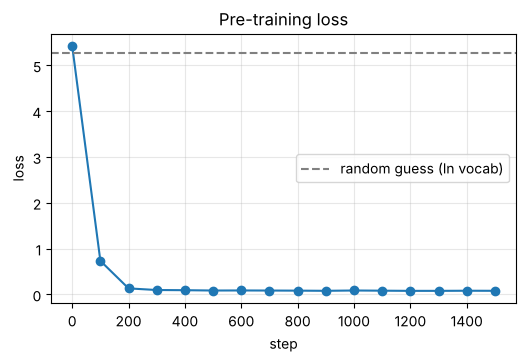

In [15]:
import matplotlib.pyplot as plt

steps, losses = zip(*pretrain_history)
plt.figure(figsize=(6, 3.5))
plt.plot(steps, losses, marker="o")
plt.axhline(math.log(vocab_size), color="gray", linestyle="--", label="random guess (ln vocab)")
plt.xlabel("step")
plt.ylabel("loss")
plt.title("Pre-training loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [16]:
torch.manual_seed(0)
print("[프리트레이닝 후 생성 결과]")
for prompt in ["오늘은", "고양이는", "질문: 겨울 날씨는 어떤가요?\n"]:
    print("-" * 40)
    print(generate_text(model, prompt))

[프리트레이닝 후 생성 결과]
----------------------------------------
오늘은 날씨가 맑고 하늘이 파랗다. 바람이 시원하게 불어서 산책하기 좋은 날이다.
고양이는 햇볕이 드는 창가에서 
----------------------------------------
고양이는 햇볕이 드는 창가에서 낮잠을 잔다. 강아지는 공원에서 공을 쫓아 뛰어다닌다.
아침에는 따뜻한 커피를 마시고
----------------------------------------
질문: 겨울 날씨는 어떤가요?
학생들은 배우기 쉬운 프로그래밍 언어이다. 많은 사람들이 파이썬으로 데이터를 분석한다.
비가 오는 날에는 우


**관찰 포인트**

- 이제 한국어 문장처럼 보이는 글자를 생성합니다. 데이터가 작아서 학습 데이터를 거의 외운 듯한 문장이 나옵니다.
- 하지만 `질문: ...`을 줘도 **답변 형식으로 대답하지 않습니다.** 프리트레이닝 데이터에 그런 형식이 없었기 때문입니다.

이것이 바로 실제 **베이스 모델(base model)** 의 모습입니다. 언어는 알지만 "질문에 답하라"는 형식은 모릅니다.
ChatGPT처럼 대답하는 모델(instruct/chat 모델)은 베이스 모델을 대화 데이터로 **파인튜닝**해서 만듭니다.

## 7. 파인튜닝: 같은 모델을 질문-답변 데이터로 더 학습하기

파인튜닝에서 바뀌는 것은 딱 세 가지입니다.

1. **시작점:** 무작위 가중치가 아니라 방금 프리트레이닝한 가중치에서 시작
2. **데이터:** `질문/답변` 형식의 작은 데이터
3. **학습률과 스텝 수:** 더 작게, 더 짧게 (이미 배운 지식을 망가뜨리지 않도록)

학습 루프 코드는 **완전히 똑같습니다.** 위에서 만든 `train` 함수를 그대로 다시 씁니다.
여기서는 모든 가중치를 학습하므로 이것이 **Full 파인튜닝**입니다.

비교를 위해 프리트레이닝이 끝난 모델을 복사해 두고, 복사본을 파인튜닝합니다.

In [17]:
import copy

base_model = model                    # 프리트레이닝만 한 모델 (베이스 모델)
ft_model = copy.deepcopy(base_model)  # 이 복사본을 파인튜닝한다

print(f"파인튜닝 전, 파인튜닝 데이터에 대한 loss: {estimate_loss(ft_model, finetune_data):.3f}")

파인튜닝 전, 파인튜닝 데이터에 대한 loss: 6.289


In [18]:
finetune_history = train(ft_model, finetune_data, max_steps=500, lr=1e-3)

step     0 | loss 6.268 |   0.1s


step   100 | loss 0.218 |   2.3s


step   200 | loss 0.095 |   4.5s


step   300 | loss 0.075 |   6.6s


step   400 | loss 0.069 |   8.5s


step   500 | loss 0.071 |  10.5s


In [19]:
def compare(prompt, max_new_tokens=40):
    torch.manual_seed(0)
    print(f"프롬프트: {prompt!r}")
    print("[베이스 모델]    ", repr(generate_text(base_model, prompt, max_new_tokens)[len(prompt):]))
    torch.manual_seed(0)
    print("[파인튜닝 모델]  ", repr(generate_text(ft_model, prompt, max_new_tokens)[len(prompt):]))
    print()

compare("질문: 겨울 날씨는 어떤가요?\n")
compare("질문: 파이썬은 어떤 언어인가요?\n")
# 파인튜닝 데이터에 없는 질문
compare("질문: 강아지는 어디에서 뛰어다니나요?\n")

프롬프트: '질문: 겨울 날씨는 어떤가요?\n'
[베이스 모델]     '비가 오는 날에는 우산을 챙겨야 한다. 겨울에는 눈이 내리고 날씨가 춥다'
[파인튜닝 모델]   '답변: 겨울에는 눈이 내리고 날씨가 춥습니다.\n질문: 비가 오면 무엇을 '

프롬프트: '질문: 파이썬은 어떤 언어인가요?\n'
[베이스 모델]     '엄마는 부엌에서 맛있는 저녁을 만든다. 아빠는 거실에서 음악을 듣는다.\n'
[파인튜닝 모델]   '답변: 파이썬은 배우기 쉬운 프로그래밍 언어입니다.\n질문: 겨울 날씨는 '

프롬프트: '질문: 강아지는 어디에서 뛰어다니나요?\n'
[베이스 모델]     '비가 오는 날에는 우산을 챙겨야 한다. 겨울에는 눈이 내리고 날씨가 춥다'
[파인튜닝 모델]   '질문: 여름에는 무엇을 하나요?\n답변: 여름에는 바다에 가서 수영을 합니'



**관찰 포인트**

- 파인튜닝한 모델은 `질문:` 다음에 `답변:`으로 시작하는 **형식**을 따릅니다. 베이스 모델은 그렇지 않습니다.
- 반면 파인튜닝 데이터에 없던 질문(강아지)에는 엉뚱한 말을 하거나, 학습 데이터의 다른 질문/답변을 외운 그대로 내놓기 쉽습니다.
  우리 모델은 파라미터 12만 개에 데이터도 몇 줄뿐이라 **일반화하지 못하고 외운 것**입니다.
  실제 LLM은 프리트레이닝에서 배운 방대한 지식 덕분에 처음 보는 질문에도 형식을 지켜 그럴듯하게 답합니다. 이게 큰 베이스 모델을 파인튜닝하는 이유입니다.

### 파인튜닝의 부작용: 망각 (Catastrophic Forgetting)

파인튜닝 모델이 원래의 일반 문장은 얼마나 잘 기억하고 있을까요? 프리트레이닝 데이터에 대한 loss를 비교해 봅시다.

In [20]:
torch.manual_seed(0)
base_pt = estimate_loss(base_model, pretrain_data)
ft_pt = estimate_loss(ft_model, pretrain_data)
base_ft = estimate_loss(base_model, finetune_data)
ft_ft = estimate_loss(ft_model, finetune_data)

print(f"{'':16}{'일반 문장 loss':>14}{'질문/답변 loss':>16}")
print(f"{'베이스 모델':16}{base_pt:>14.3f}{base_ft:>16.3f}")
print(f"{'파인튜닝 모델':15}{ft_pt:>14.3f}{ft_ft:>16.3f}")

                    일반 문장 loss      질문/답변 loss
베이스 모델                   0.081           6.237
파인튜닝 모델                 0.767           0.073


파인튜닝 모델은 질문/답변 데이터의 loss가 크게 줄었지만, 일반 문장에 대한 loss는 올라갔을 수 있습니다.
새 데이터에 맞추느라 원래 배운 것을 일부 잊어버린 것입니다. 이 현상을 **catastrophic forgetting**이라고 합니다.

그래서 파인튜닝에서는 보통

- 학습률을 작게, 스텝 수를 적게 잡고
- 일부 가중치만 학습하는 **LoRA** 같은 방법을 쓰기도 합니다 (3단계).

> 🧪 **실험해 보기:** 위의 `train(ft_model, finetune_data, max_steps=500, lr=1e-3)`에서 `lr`을 `3e-3`이나 `1e-4`로, `max_steps`를 `100`이나 `2000`으로 바꿔 보세요.
> 질문/답변 형식은 얼마나 빨리 배우는지, 일반 문장 loss는 얼마나 나빠지는지 비교해 보면 학습률의 역할을 체감할 수 있습니다.
> (다시 실행할 때는 `ft_model = copy.deepcopy(base_model)` 셀부터 실행하세요.)

### 참고: 실제 파인튜닝에서는 보통 "답변 부분"만 loss를 계산합니다

우리는 질문과 답변 전체에 대해 다음 토큰 예측 loss를 계산했습니다.
실제 대화형 파인튜닝(SFT, Supervised Fine-Tuning)에서는 **질문 부분의 loss는 무시하고 답변 토큰에 대해서만** loss를 계산하는 경우가 많습니다.
모델이 질문을 외우는 것이 아니라 답변하는 법을 배우게 하려는 것입니다. PyTorch에서는 무시할 위치의 정답을 `-100`으로 두면 `F.cross_entropy`가 자동으로 건너뜁니다.

In [21]:
logits = torch.randn(1, 6, vocab_size)                     # 6개 위치의 예측
targets = torch.tensor([[5, 8, 2, 7, 1, 3]])
masked_targets = torch.tensor([[-100, -100, -100, 7, 1, 3]])  # 앞 3개(질문 부분)는 무시

print("전체 loss         :", F.cross_entropy(logits.view(-1, vocab_size), targets.view(-1)).item())
print("답변 부분만 loss  :", F.cross_entropy(logits.view(-1, vocab_size), masked_targets.view(-1)).item())
print("직접 계산 (뒤 3개):", F.cross_entropy(logits[0, 3:], targets[0, 3:]).item())

전체 loss         : 5.707517623901367
답변 부분만 loss  : 5.788669109344482
직접 계산 (뒤 3개): 5.788669109344482


## 8. 실제 LLM을 파인튜닝하려면 GPU 메모리가 얼마나 필요할까?

다음 단계로 가기 전에 중요한 계산을 해 봅시다. 이게 **Full 파인튜닝을 할지 LoRA를 할지** 결정하는 기준입니다.

Full 파인튜닝(AdamW 사용)을 할 때 GPU 메모리에 올라가는 것:

| 항목 | fp32 기준 파라미터당 바이트 | 설명 |
|---|---|---|
| 가중치 | 4 | 모델 자체 |
| Gradient | 4 | 역전파로 계산된 기울기 |
| AdamW 상태 | 8 | 옵티마이저가 저장하는 값 2개 (momentum, variance) |
| **합계** | **16** | + activation(중간 계산값) 메모리는 별도 |

즉 Full 파인튜닝은 대략 **파라미터 수 × 16바이트 + α** 가 필요합니다.
LoRA는 원래 가중치를 얼려 두므로 gradient와 옵티마이저 상태가 아주 작은 LoRA 파라미터에만 생깁니다. 그래서 대략 **가중치 크기 + α** 정도면 됩니다.

In [22]:
def estimate_memory_gb(n_params, method):
    if method == "full_fp32":
        bytes_per_param = 16  # 가중치 4 + gradient 4 + AdamW 8
    elif method == "lora_fp16":
        bytes_per_param = 2   # 얼린 가중치를 fp16(2바이트)으로만 올림 (LoRA 파라미터는 무시할 만큼 작음)
    return n_params * bytes_per_param / 1024**3

models = {
    "우리 TinyGPT": n_params,
    "GPT-2 small (124M)": 124e6,
    "Qwen2.5-0.5B": 494e6,
    "Qwen2.5-1.5B": 1.54e9,
    "Llama-3-8B": 8e9,
}

print(f"{'모델':22}{'Full (fp32)':>14}{'LoRA (fp16)':>14}")
for name, n in models.items():
    print(f"{name:22}{estimate_memory_gb(n, 'full_fp32'):>11.2f} GB{estimate_memory_gb(n, 'lora_fp16'):>11.2f} GB")

print("\n※ activation 메모리는 제외한 대략적인 값입니다. 실제로는 배치 크기와 시퀀스 길이에 따라 더 필요합니다.")

모델                       Full (fp32)   LoRA (fp16)
우리 TinyGPT                   0.00 GB       0.00 GB
GPT-2 small (124M)           1.85 GB       0.23 GB
Qwen2.5-0.5B                 7.36 GB       0.92 GB
Qwen2.5-1.5B                22.95 GB       2.87 GB
Llama-3-8B                 119.21 GB      14.90 GB

※ activation 메모리는 제외한 대략적인 값입니다. 실제로는 배치 크기와 시퀀스 길이에 따라 더 필요합니다.


**RTX 3060 기준으로 해석하면**

- **GPT-2 small (124M):** Full 파인튜닝 약 2GB → 6GB, 12GB 어디서든 가능
- **Qwen2.5-0.5B:** Full 파인튜닝 약 7.4GB → 12GB에서는 가능, 6GB에서는 빠듯함 (fp16/bf16 혼합 정밀도, 작은 배치, gradient checkpointing 같은 절약 기법 필요)
- **1.5B 이상:** Full 파인튜닝은 어렵고 **LoRA**(또는 4bit 양자화를 더한 QLoRA)가 현실적

그래서 이 과정은
**2단계에서 작은 모델로 Full 파인튜닝 → 3단계에서 LoRA로 같은 작업을 하고 메모리 비교** 순서로 진행합니다.

## 9. 정리

| 개념 | 한 줄 요약 |
|---|---|
| 토큰화 | 텍스트 ↔ 정수 ID. 실제 LLM은 BPE 같은 서브워드 토크나이저 사용 |
| 다음 토큰 예측 | 텍스트를 한 칸 밀면 정답이 됨. 라벨링 불필요 |
| Cross entropy loss | −log(정답 토큰의 확률). 무작위 모델은 ln(vocab)에서 시작 |
| 학습 루프 | 배치 → 순전파/loss → zero_grad → backward → step. LLM도 똑같음 |
| 프리트레이닝 | 무작위 가중치 + 대량의 일반 텍스트 → 언어를 아는 베이스 모델 |
| 파인튜닝 | 프리트레이닝된 가중치 + 작은 목적 데이터 + 작은 학습률 → 원하는 형식/작업 |
| Full vs LoRA | 전체 가중치 학습(메모리 ≈ 파라미터×16B) vs 작은 보조 가중치만 학습 |

### 연습 문제

1. `TinyGPT`의 `n_layer`, `n_embd`를 키우면 파라미터 수와 최종 loss가 어떻게 변하나요? 학습 시간은요?
2. `block_size`를 8로 줄이면 생성되는 문장의 질이 어떻게 달라지나요? 왜 그럴까요?
3. `generate_text`의 `temperature`를 0.3, 1.5로 바꿔서 생성해 보세요. 어떤 차이가 있나요?
4. `finetune_text`에 나만의 질문/답변 쌍을 몇 개 추가하고 다시 파인튜닝해 보세요. (새 글자가 들어가면 어휘가 바뀌므로 토큰화 셀부터 다시 실행해야 합니다.)

### 다음 단계

**02. Full 파인튜닝 실습**에서는 Hugging Face `transformers`로 이미 프리트레이닝된 진짜 모델(GPT-2 또는 Qwen2.5-0.5B)을 불러와 파인튜닝합니다.
이 노트북에서 직접 짠 토크나이저, 학습 루프, loss가 라이브러리에서는 어떻게 쓰이는지 연결해 보겠습니다.